# COMP 551 Assignment 3

## Task 1: Acquire the data

In [61]:
#!pip install torchvision

In [62]:
import torch
import numpy as np
from torchvision import datasets
from torchvision import transforms
from torch.utils.data import DataLoader

### **Step 1: Load Dataset**

In [63]:
train_dataset_raw = datasets.FashionMNIST(root='./data', train=True, download=True,
                                      transform=transforms.ToTensor())
test_dataset_raw = datasets.FashionMNIST(root='./data', train=False, download=True,
                                      transform=transforms.ToTensor())

In [64]:
image, label = train_dataset_raw[0]
print(type(image))
print(image.shape) 
print(image.dtype)
print(image.device) 
print(f"Train partition: {len(train_dataset_raw)} images")
print(f"Test partition:  {len(test_dataset_raw)} images")

<class 'torch.Tensor'>
torch.Size([1, 28, 28])
torch.float32
cpu
Train partition: 60000 images
Test partition:  10000 images


### **Step 2: Normalize Dataset**

In [65]:
sum = 0.0
squared_sum = 0.0
N = 0
train_loader = DataLoader(train_dataset_raw, batch_size=1000, shuffle=False)
for data, _ in train_loader: # Accumulative sum and std throughout data
    sum += data.sum(dim=[0, 2, 3])
    squared_sum += (data ** 2).sum(dim=[0, 2, 3])
    N += data.numel()
mean = (sum / N).item()
std = (torch.sqrt((squared_sum / N) - (mean ** 2))).item()
print(mean)
print(std)

0.28604063391685486
0.3530242443084717


In [66]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((mean,), (std,))
])
train_dataset = datasets.FashionMNIST(root='./data', train=True, download=True,
                                      transform=transform)
test_dataset = datasets.FashionMNIST(root='./data', train=False, download=True,
                                      transform=transform)                                     

### **Step 3: Create Training and Validation Set**

In [67]:
from torch.utils.data import random_split

split_ratio = 0.8
train_size = int(split_ratio * len(train_dataset))
val_size = len(train_dataset) - train_size

train_dataset, val_dataset = random_split(train_dataset, [train_size, val_size])

print(f"Train size: {train_size}")
print(f"Validation size: {val_size}")

Train size: 48000
Validation size: 12000


In [68]:
from torch.utils.data import DataLoader

batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

### Step 4: Flatten

In [69]:
# Training set
loader_train = DataLoader(train_dataset, batch_size=len(train_dataset), shuffle=False)
x_train, y_train = next(iter(loader_train))                       
x_train = x_train.flatten(start_dim=1).numpy()
y_train = y_train.numpy()

#Validation set
loader_val = DataLoader(val_dataset, batch_size=len(val_dataset), shuffle=False)
x_val, y_val = next(iter(loader_val))                       
x_val = x_val.flatten(start_dim=1).numpy()
y_val = y_val.numpy()

#test set
loader_test = DataLoader(test_dataset, batch_size=len(test_dataset), shuffle=False)
x_test, y_test = next(iter(loader_test))                       
x_test = x_test.flatten(start_dim=1).numpy()
y_test = y_test.numpy()
print(f"x_train: {x_train.shape}, y_train: {y_train.shape}")
print(f"x_val:   {x_val.shape},   y_val:   {y_val.shape}")
print(f"x_test:  {x_test.shape},  y_test:  {y_test.shape}")
print(f"train mean {x_train.mean():.3f}, train std {x_train.std():.3f}")
print(f"train mean {x_val.mean():.3f}, train std {x_val.std():.3f}")
print(f"test  mean {x_test.mean():.3f},  test  std {x_test.std():.3f}")


x_train: (48000, 784), y_train: (48000,)
x_val:   (12000, 784),   y_val:   (12000,)
x_test:  (10000, 784),  y_test:  (10000,)
train mean -0.001, train std 1.000
train mean 0.002, train std 1.000
test  mean 0.002,  test  std 0.998


### Exploratory Data Analysis

In [70]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

#### 1. Dataset structure

In [71]:
for root, dirs, files in os.walk('./data/FashionMNIST'):

    level = root.replace('./data/FashionMNIST', "").count(os.sep)

    indent = " " * 4 * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:]:
        print(f"{indent}    {file}")

print(train_dataset_raw)
print("Images shape:", train_dataset_raw.data.shape)
print("Labels shape:", train_dataset_raw.targets.shape)
class_names = train_dataset_raw.classes

print("Number of classes:", len(class_names))
for class_id, class_name in enumerate(class_names):
    print(class_id, class_name)


FashionMNIST/
    raw/
        t10k-images-idx3-ubyte
        t10k-labels-idx1-ubyte
        train-images-idx3-ubyte
        t10k-images-idx3-ubyte.gz
        train-images-idx3-ubyte.gz
        train-labels-idx1-ubyte.gz
        train-labels-idx1-ubyte
        t10k-labels-idx1-ubyte.gz
Dataset FashionMNIST
    Number of datapoints: 60000
    Root location: ./data
    Split: Train
    StandardTransform
Transform: ToTensor()
Images shape: torch.Size([60000, 28, 28])
Labels shape: torch.Size([60000])
Number of classes: 10
0 T-shirt/top
1 Trouser
2 Pullover
3 Dress
4 Coat
5 Sandal
6 Shirt
7 Sneaker
8 Bag
9 Ankle boot


#### 2. Class Distribution - images per category

         Class  Train  Validation  Test  Total
0  T-shirt/top   4813        1187  1000   7000
1      Trouser   4772        1228  1000   7000
2     Pullover   4816        1184  1000   7000
3        Dress   4834        1166  1000   7000
4         Coat   4807        1193  1000   7000
5       Sandal   4876        1124  1000   7000
6        Shirt   4760        1240  1000   7000
7      Sneaker   4793        1207  1000   7000
8          Bag   4778        1222  1000   7000
9   Ankle boot   4751        1249  1000   7000


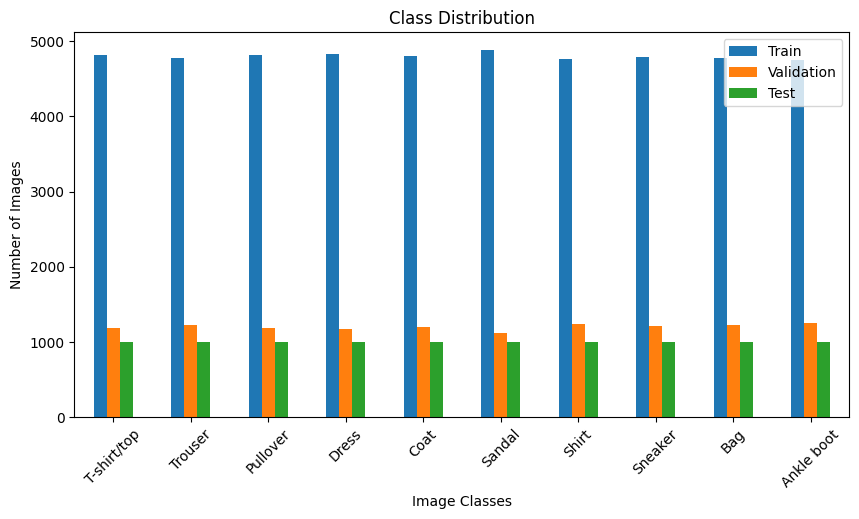

In [72]:
class_names = train_dataset_raw.classes

splits = {
    "Train": y_train,
    "Validation": y_val,
    "Test": y_test
}

class_counts = {"Class": class_names}

for split_name, labels in splits.items():
    class_counts[split_name] = np.bincount(labels, minlength=10)

class_df = pd.DataFrame(class_counts)
class_df["Total"] = class_df[["Train", "Validation", "Test"]].sum(axis=1)

print(class_df)

class_df.plot(
    kind="bar",
    x="Class",
    y=["Train", "Validation", "Test"],
    figsize=(10, 5)
)

plt.title("Class Distribution")
plt.xlabel("Image Classes")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.show()

#### 3. Random raw images

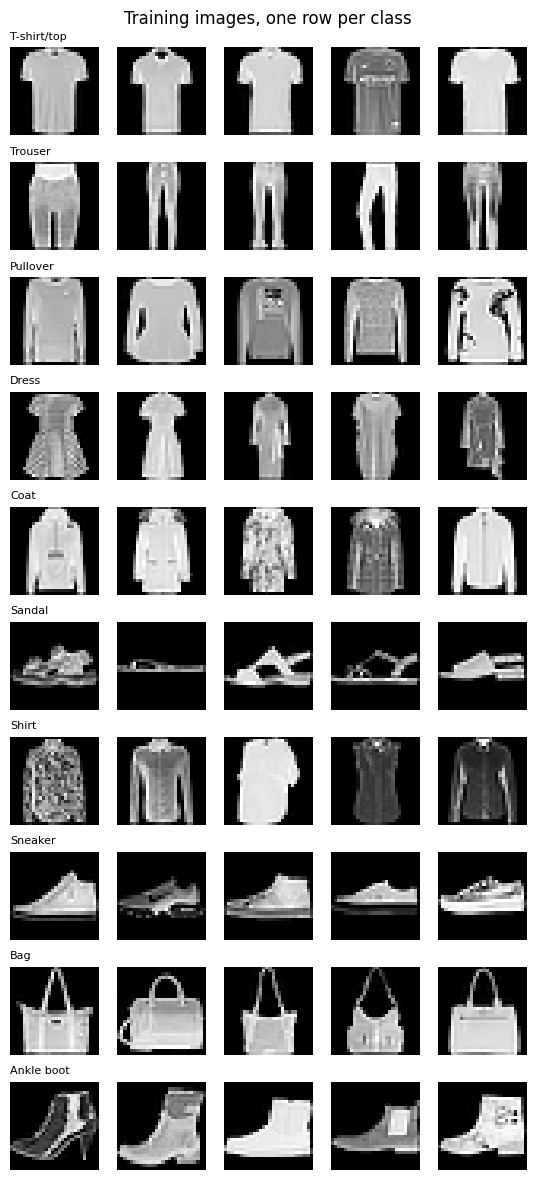

In [73]:
n_show = 5
fig, axes = plt.subplots(10, n_show, figsize=(n_show * 1.1, 10 * 1.2))
for c in range(10):
    examples = np.where(y_train == c)[0][:n_show]
    for j, i in enumerate(examples):
        axes[c, j].imshow(x_train[i].reshape(28, 28), cmap='gray')
        axes[c, j].axis('off')
    axes[c, 0].set_title(class_names[c], fontsize=8, loc='left')
plt.suptitle('Training images, one row per class')
plt.tight_layout()
plt.show()

#### 4.Pixel distribution — mean, std, intensity

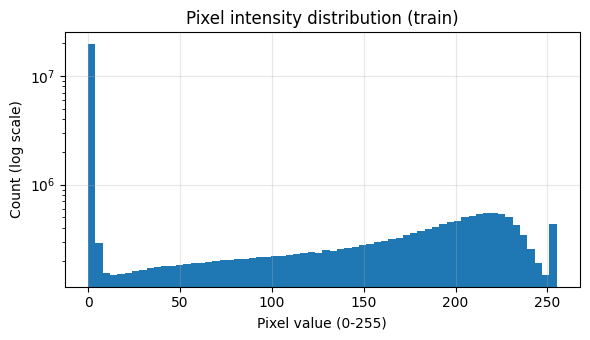

In [89]:
x_all_train = train_dataset_raw.data.numpy()
y_all_train = train_dataset_raw.targets.numpy()
x_all_test = test_dataset_raw.data.numpy()

# Same train / validation split as y_train and y_val
train_idx = np.array(train_dataset.indices)
val_idx = np.array(val_dataset.indices)
X_train = x_all_train[train_idx]
X_val = x_all_train[val_idx]

plt.figure(figsize=(6, 3.5))
plt.hist(X_train.ravel(), bins=64, log=True)
plt.xlabel('Pixel value (0-255)')
plt.ylabel('Count (log scale)')
plt.title('Pixel intensity distribution (train)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#### 5. Data integrity -- corrupted images


In [91]:
invalid = []
for i in range(len(train_dataset_raw)):              # reading every image like during training
    try:
        img, lable = train_dataset_raw[i]
    except Exception as e:
        invalid.append(("train", i))
for i in range(len(test_dataset_raw)):
    try:
        img, lable = test_dataset_raw[i]
    except Exception as e:
        invalid.append(('test', i))
print(f"Invalid images: {len(invalid)}")

for name, x, y in [('train partition', x_all_train, y_all_train), ('test partition', x_all_test, y_test)]:
    print(f"\n{name}:")
    print(f"  all images 28x28:        {x.shape[1:] == (28, 28)}")
    print(f"  pixel range:             [{x.min()}, {x.max()}]")
    print(f"  NaN values:              {np.isnan(x.astype(float)).sum()}")
    print(f"  labels in [0,9]:          {set(np.unique(y)) <= set(range(10))}")
    print(f"  completely blank images: {(x.reshape(len(x), -1).max(axis=1) == 0).sum()}")

Invalid images: 0

train partition:
  all images 28x28:        True
  pixel range:             [0, 255]
  NaN values:              0
  labels in [0,9]:          True
  completely blank images: 0

test partition:
  all images 28x28:        True
  pixel range:             [0, 255]
  NaN values:              0
  labels in [0,9]:          True
  completely blank images: 0


#### 6. Data leakage

In [ ]:
# 6.1 image index in both training and validation
print(f"Indices shared by train and validation: {len(set(train_idx) & set(val_idx))}")

Indices shared by train and validation: 0


## Task 2: Implement a Multilayer Perceptron

Our model is
$$
\hat{y} = \sigma \left ( W \sigma \left ( V x \right ) \right)
$$
where we have $M$ hidden units and $D$ input features -- that is $W \in \mathbb{R}^{M}$, and $V \in \mathbb{R}^{M \times D}$. 

An MLP is composed of three types of layers: 

(1) an input layer -> flattened 784 pixels

(2) hidden layers -> every layer: $z = h(Wx+b)$ (linear transformation -> activate function)

    - Activate Function: ReLU, Tanh, Leaky-ReLU

(3) an output layer -> the probabillity of 10 categories (softmax)

Implementation should include 

    - backpropagation 

    - mini-batch gradient descent algorithm

- [] gamma is also a learnable parameter  

In [ ]:
#Activate Function
relu = lambda a: np.maximum(0, a)
relu_grad = lambda a: (a > 0).astype(float)                          

tanh = lambda a: np.tanh(a)
tanh_grad = lambda a: 1 - np.tanh(a) ** 2                            

leaky_relu = lambda a: np.maximum(0, a) + 0.01 * np.minimum(0, a)   #gamma is also a learnable parameter  
leaky_relu_grad = lambda a: np.where(a > 0, 1., 0.01)

activations = {'relu': (relu, relu_grad),
               'tanh': (tanh, tanh_grad),
               'leaky_relu': (leaky_relu, leaky_relu_grad)}

In [ ]:
#The constructor for the class should take as input 
# the activation function (e.g., ReLU), 
# the number of hidden layers (e.g., 2) 
# the number of units in the hidden layers (e.g., [64, 64]) 
# initialize the weights and biases (with an initializer of your choice) 
# as well as other important properties of the MLP.
class MLP:
    
    def __init__(self, activation, n_hidden_layers, hidden_units, input_dim , output_dim):
        '''
        Initialize a multilayer perceptron with a softmax output layer.

        Architecture: x -> [W1,b1] -> h -> [W2,b2] -> h -> ... -> [WL,bL] -> softmax -> yh

        Parameters:
        activation: hidden activation, 'relu', 'tanh' or 'leaky_relu'
        n_hidden_layers: number of hidden layers 
        hidden_units: list with the number of units of each hidden layer
        input_dim: number of input features D
        output_dim: number of classes C
        l1, l2: strength of the L1 / L2 penalty on the weights
        '''
        self.n_hidden_layers = n_hidden_layers
        self.hidden_units = hidden_units
        self.h, self.h_grad = activations[activation]
        self.input_dim = input_dim
        self.output_dim = output_dim
        
        layer_sizes = [input_dim] +list(hidden_units)+[output_dim]
        # Store parameters as a list for the optimizer
        self.params = [] # [W1,b1,W2,b2,...,Wl,bl]

        for fan_in, fan_out in zip(layer_sizes[:-1],layer_sizes[1:]):

            W = np.random.randn(fan_in, fan_out) * np.sqrt(
                2 / (fan_in + fan_out)
            )

            b = np.zeros(fan_out)

            self.params.extend([W, b])
            
    def fit(self, x, y, optimizer):
        """
        Fit the MLP model using backpropagation and gradient descent.
        
        Parameters:
        x: input features, shape (N, D) where N=samples, D=features
        y: binary labels (0 or 1), shape (N,)
        optimizer: optimizer object with a run() method (e.g., GradientDescent)
        
        Returns:
        self: fitted model with learned parameters stored in self.params
        """
        N, D = x.shape
        
        def gradient(x, y, params):
            """
            Compute gradients for both layers using backpropagation.
            
            Parameters:
            x: input features, shape (N, D)
            y: true labels, shape (N,)
            params: list [v, w] where v is (D, M) and w is (M,)
            
            Returns:
            dparams: list [dv, dw] containing gradients for V and W
            
            Implementation note: This computes gradients for ALL parameters
            simultaneously using vectorized operations (not one at a time).
            """
            v, w = params  # v: (D, M), w: (M,)
            
            # ===== Forward pass =====
            # Compute hidden layer activations
            # x @ v: (N, D) @ (D, M) = (N, M)
            # Each of N samples produces M hidden unit pre-activations
            # logistic applies element-wise: z[i,j] = σ(sum_d x[i,d] * v[d,j])
            z = logistic(np.dot(x, v))  # Shape: (N, M)
            
            # Compute output predictions
            # z @ w: (N, M) @ (M,) = (N,)
            # For each sample: yh[i] = σ(sum_m z[i,m] * w[m])
            yh = logistic(np.dot(z, w))  # Shape: (N,)
            
            # ===== Backward pass (backpropagation) =====
            # Output layer gradient
            # dy is the error at the output: ŷ - y
            dy = yh - y  # Shape: (N,)
            
            # Gradient for output weights W
            # z.T @ dy: (M, N) @ (N,) = (M,)
            # dw[j] = (1/N) * sum_i z[i,j] * dy[i]
            # This tells us how to adjust each output weight
            dw = np.dot(z.T, dy) / N  # Shape: (M,)
            
            # Gradient flowing back to hidden layer
            # np.outer(dy, w): (N,) ⊗ (M,) = (N, M)
            # outer product: dz[i,j] = dy[i] * w[j]
            # This distributes the output error to each hidden unit
            # proportional to the weight connecting that unit to the output
            dz = np.outer(dy, w)  # Shape: (N, M)
            
            # Gradient for hidden layer weights V
            # Chain rule: need to multiply by derivative of sigmoid
            # σ'(a) = σ(a) * (1 - σ(a)), so we use z * (1 - z)
            # dz * z * (1-z) applies the sigmoid derivative element-wise
            # x.T @ (dz * z * (1-z)): (D, N) @ (N, M) = (D, M)
            # dv[d,j] = (1/N) * sum_i x[i,d] * dz[i,j] * z[i,j] * (1 - z[i,j])
            dv = np.dot(x.T, dz * z * (1 - z)) / N  # Shape: (D, M)
            
            dparams = [dv, dw]
            return dparams
        
        # Initialize weights with small random values (breaking symmetry)
        # Random initialization prevents all hidden units from learning the same thing
        # Scale by 0.01 to keep initial values small
        w = np.random.randn(self.M) * .01  # Shape: (M,)
        v = np.random.randn(D, self.M) * .01  # Shape: (D, M)
        
        # Store parameters as a list for the optimizer
        params0 = [v, w]
        
        # Run optimization (gradient descent updates params iteratively)
        self.params = optimizer.run(gradient, x, y, params0)
        
        return self
    
    def predict(self, x):
        """
        Predict class probabilities for input x using learned parameters.
        
        Parameters:
        x: input features, shape (N, D)
        
        Returns:
        yh: predicted probabilities P(y=1|x), shape (N,)
        """
        v, w = self.params  # Extract learned weights
        
        # Forward pass (same as in gradient computation)
        # Hidden layer: x @ v then apply sigmoid
        z = logistic(np.dot(x, v))  # Shape: (N, M)
        
        # Output layer: z @ w then apply sigmoid
        yh = logistic(np.dot(z, w))  # Shape: (N,)
        
        return yh